# First-arrival user-data inversion: solver, coverage and sensitivity

**Level 3 — Applied research workflow** · 45 min · prerequisites: levels 1–2, travel-time tomography and weighted least squares.


## Objectives

Compare the local first-arrival user-data calculation with the synthetic control that defines its ground truth; inspect geometric support and signed travel-time residuals; quantify how declared uncertainty and regularization alter the same executable solve.


## Setup

Run in the pinned notebook environment with `scripts/setup.ps1 -Notebooks` (Windows) or `scripts/setup.sh --notebooks` (Linux/macOS). Exact packages: `pip install numpy==2.2.6 scipy==1.15.2 matplotlib==3.10.8`. The following cell prints the active versions.


In [1]:
# Execute the repository user-data calculation and report the pinned runtime.
from importlib.metadata import version
from pathlib import Path
import sys, json
import numpy as np
import matplotlib.pyplot as plt
root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data-pipeline").is_dir())
sys.path.insert(0, str(root / "data-pipeline"))
import velocity_user_data as user_velocity
from velocity_validation import acquisition, background, cell_length_matrix

rays = acquisition("A")
truth = background()
A = cell_length_matrix(rays)
rng = np.random.default_rng(20261027)
sigma = np.full(len(rays), 0.001)
observed = A @ (1.0 / truth.ravel()) + rng.normal(0.0, sigma)
request = {
    "schema": user_velocity.SCHEMA, "id": "m12-notebook-control",
    "source": {"citation": "Authored reproducible teaching control", "rights": "owner-permitted", "scope": "synthetic-control"},
    "frame": "local-x-z-down", "units": {"distance": "m", "time": "s", "velocity": "m/s"},
    "ray_ids": [f"ray-{i:03d}" for i in range(len(rays))], "rays_m": rays.tolist(),
    "times_s": observed.tolist(), "sigma_s": sigma.tolist(), "lambda": 100.0,
}
result = user_velocity.calculate(json.dumps(request, allow_nan=False).encode())
classical = result["results"]["classical"]
velocity = np.asarray(classical["velocity_m_s"])
coverage = np.asarray(result["coverage_m"])
residual_ms = 1000.0 * np.asarray(classical["residual_s"])
print("engine:", result["engine"])
print("rays:", len(rays), "grid:", velocity.shape, "WRMS:", round(classical["data_wrms"], 3), "clipped cells:", classical["clipped_cells"])
print("claim boundary:", result["claims"])

print("Pinned runtime:", {name: version(name) for name in ("numpy", "scipy", "matplotlib")})


engine: {'numpy': '2.2.6', 'scipy': '1.15.2', 'user_tool_sha256': '3dc6ee5f7ca5123aeceada0422902f9aa2d721c24ca1b93c694d2b70f5109c4b', 'velocity_operator_sha256': '2b9ed95d3ba7b1b0f9f80167fa610640dc75c8a142dafb9f7f09791b96a1fd44', 'checkpoint_sha256': None, 'checkpoint_protocol': None, 'refinement_code_sha256': None}
rays: 128 grid: (16, 16) WRMS: 0.115 clipped cells: 0
claim boundary: {'field_truth_known': False, 'field_validated': False, 'heldout_advantage': False, 'online_admitted': False}
Pinned runtime: {'numpy': '2.2.6', 'scipy': '1.15.2', 'matplotlib': '3.10.8'}


## Data

The control uses an authored acquisition, fixed seed 20261027, and 1 ms standard deviations. Synthetic observations use the same declared straight-ray cell-length operator. The estimator receives rays, noisy times, uncertainties, frame and regularization; truth is used only afterward for a control-only error calculation.


## Method

For fixed straight rays, travel time is approximately \(t=A s\), where \(A_{ij}\) is path length (m) of ray \(i\) through cell \(j\), and \(s_j=1/v_j\) is slowness (s/m). The product calculator validates the closed user-data contract, solves its regularized weighted system, reports coverage and residuals, and verifies its output generation. This lesson calls the API in `data-pipeline/velocity_user_data.py`; the documented file interface is `scripts/process_velocity.py`. It imports the solver rather than reimplementing it.


## Comparison

First-arrival tomography estimates structure from travel-time observations, an acquisition and a propagation model. The straight-ray linearization supports transparent weighting and sensitivity analysis but omits bending and nonlinear refracted travel times; product M09 is distinct. The pyGIMLi Königsee example provides context for a separate field refraction workflow. Optional M12 frozen-CNN inference is experimental: its retained matched held-out comparison loses to the classical estimate.


## Results

The calculation reports its engine, ray count, grid, weighted data WRMS and clipped cells. The panels separate estimated velocity, path-length support and observed-minus-predicted time. Sensitivity runs change the regularization coefficient or scale all declared standard deviations and call the same product method again. Truth RMSE is available only for this synthetic control; user field data have no supplied truth raster.


### Plot model, geometric support and signed residuals.


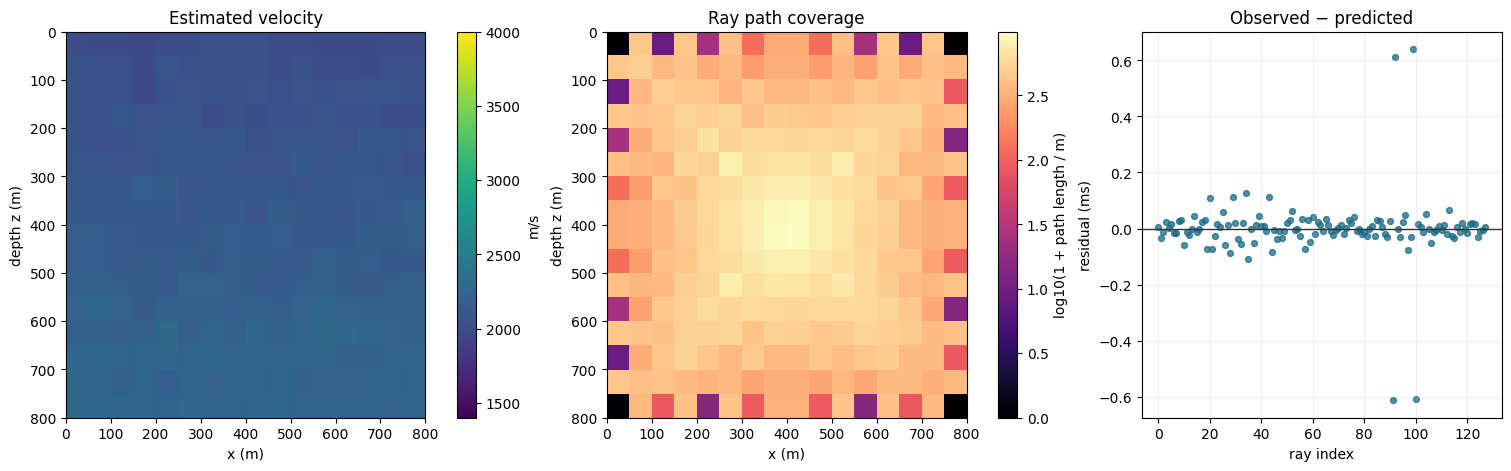

In [2]:
# Plot model, geometric support and signed data residuals as separate diagnostics.
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), constrained_layout=True)
im = axes[0].imshow(velocity, origin="upper", aspect="auto", extent=(0, 800, 800, 0), cmap="viridis", vmin=1400, vmax=4000)
axes[0].set(title="Estimated velocity", xlabel="x (m)", ylabel="depth z (m)")
fig.colorbar(im, ax=axes[0], label="m/s")
cm = axes[1].imshow(np.log10(1 + coverage), origin="upper", aspect="auto", extent=(0, 800, 800, 0), cmap="magma")
axes[1].set(title="Ray path coverage", xlabel="x (m)", ylabel="depth z (m)")
fig.colorbar(cm, ax=axes[1], label="log10(1 + path length / m)")
axes[2].axhline(0, color="#333333", lw=1)
axes[2].scatter(np.arange(len(residual_ms)), residual_ms, s=18, alpha=.75, color="#176b87")
axes[2].set(title="Observed − predicted", xlabel="ray index", ylabel="residual (ms)")
axes[2].grid(alpha=.2)
plt.show()


### Rerun the solver after changing declared parameters.


In [3]:
# Recompute the product estimator for declared changes; this is sensitivity analysis, not parameter selection.
def solve_with(lam, sigma_scale=1.0):
    changed = dict(request)
    changed["lambda"] = float(lam)
    changed["sigma_s"] = (sigma * sigma_scale).tolist()
    return user_velocity.calculate(json.dumps(changed, allow_nan=False).encode())["results"]["classical"]

variants = [(1.0, 1.0), (100.0, 1.0), (10000.0, 1.0), (100.0, 10.0)]
summary = []
for lam, sigma_scale in variants:
    out = solve_with(lam, sigma_scale)
    model = np.asarray(out["velocity_m_s"])
    summary.append((lam, sigma_scale, float(np.sqrt(np.mean((model-truth)**2))), float(out["data_wrms"])))
print("lambda | sigma multiplier | model RMSE (m/s; synthetic truth only) | data WRMS")
for row in summary:
    print(f"{row[0]:7g} | {row[1]:16g} | {row[2]:36.2f} | {row[3]:.3f}")


lambda | sigma multiplier | model RMSE (m/s; synthetic truth only) | data WRMS
      1 |                1 |                                28.14 | 0.110
    100 |                1 |                                26.56 | 0.115
  10000 |                1 |                                11.56 | 0.591
    100 |               10 |                                11.56 | 0.059


## Summary

Coverage is path length, not resolution or confidence. `data_wrms` is relative to supplied uncertainties, not an independent accuracy measure. The linearized solve assumes fixed straight paths, source timing and a local x–z-down frame; it does not estimate origin time, refraction, bent rays or a wavefield. Slowness clipping is not a certified box-constrained optimum. Strong heterogeneity requires a validated nonlinear ray or wave-equation method. No learned-method advantage or field validity is claimed.


## References

- [pyGIMLi Königsee refraction example](https://www.pygimli.org/_examples_auto/2_seismics/plot_04_koenigsee/) — context for a separate field refraction workflow.
- [pyGIMLi inversion guide](https://www.pygimli.org/user-guide/inversion/) — inverse-problem and regularization context.
